# NIST20 baseline vs MBFS — h4 peak-coverage comparison

Compare two NIST20 `d3` fragmentation DAG datasets:

| Config | Path | `multi_cut_bfs` |
|---|---|---|
| **baseline** | `nist20_ma_mi_d3_h4_isoFalse_smpFalse` | False |
| **mbfs** | `nist20_ma_mi_d3_h4_isoFalse_smpFalse_mbfs` | True |

Question: at `h4` (up to 4 H-shifts, 0.01 Da tolerance), **which molecules now have more peaks
explained** (higher intensity-weighted `wrecall_0.01_h4`) under mbfs vs baseline — and does this
differ for CMF-adduct spectra vs direct-charge ([M+H]+/[M-H]-) spectra?

CMF (charge migration fragmentation) status is not a column in the stats dataframes — it is
derived per-spectrum from `prec_type` (see `PREC_TYPE_TO_CMF_MASS_DIFF` in
`src/fragnnet/utils/formula_utils.py`).

In [1]:
import io
import json
import tarfile
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

FRAG_DP = Path("../../data/frag")
PROC_DP = Path("../../data/proc/nist20")

CONFIGS = {
    "baseline": FRAG_DP / "nist20_ma_mi_d3_h4_isoFalse_smpFalse",
    "mbfs": FRAG_DP / "nist20_ma_mi_d3_h4_isoFalse_smpFalse_mbfs",
}

DF_NAMES = ["spec_stats_df", "mol_stats_df", "m_spec_stats_df", "m_mol_stats_df"]

TOL = "0.01"
H = 4
WCOL = f"wrecall_{TOL}_h{H}"
RCOL = f"recall_{TOL}_h{H}"

# Direct-charge adducts: only delta_h=0 is a real CMF peak (proton/electron-only carrier).
# All other adducts in PREC_TYPE_TO_CMF_MASS_DIFF use full charge-migration H-shift range.
DIRECT_CHARGE_PREC_TYPES = {"[M+H]+", "[M-H]-"}
CMF_PREC_TYPES = {
    "[M+H]+", "[M+Na]+", "[M+H+2i]+", "[M+K]+", "[M+NH4]+", "[M-H2O+H]+",
    "[M-2H2O+H]+", "[M+H-NH3]+",
    "[M-H]-", "[M-H-CO2]-", "[M+Cl]-", "[M-H-H2O]-", "[M-H+2i]-",
    "[M+CH3COOH-H]-", "[M+CH3COO]-", "[M+HCOOH-H]-",
} - DIRECT_CHARGE_PREC_TYPES

In [2]:
def load_dfs(path: Path) -> dict[str, pd.DataFrame]:
    """Load all stats pkl files from a directory or a .tar archive."""
    dfs = {}
    if path.suffix == ".tar":
        with tarfile.open(path) as tf:
            members = {Path(m.name).name: m for m in tf.getmembers() if m.name.endswith(".pkl")}
            for name in DF_NAMES:
                fname = f"{name}.pkl"
                if fname in members:
                    f = tf.extractfile(members[fname])
                    dfs[name] = pd.read_pickle(io.BytesIO(f.read()))
        with tarfile.open(path) as tf:
            for m in tf.getmembers():
                if m.name.endswith("global_stats.json"):
                    f = tf.extractfile(m)
                    dfs["global_stats"] = json.load(f)
    else:
        for name in DF_NAMES:
            pkl_path = path / f"{name}.pkl"
            if pkl_path.exists():
                dfs[name] = pd.read_pickle(pkl_path)
        gs_path = path / "global_stats.json"
        if gs_path.exists():
            dfs["global_stats"] = json.loads(gs_path.read_text())
    return dfs


def _downcast_dfs(dfs: dict) -> dict:
    """Downcast float64 columns to float32 to halve memory usage."""
    for k, v in dfs.items():
        if isinstance(v, pd.DataFrame):
            f64_cols = v.select_dtypes(include="float64").columns
            dfs[k] = v.astype({c: "float32" for c in f64_cols})
    return dfs


all_dfs = {name: _downcast_dfs(load_dfs(path)) for name, path in CONFIGS.items()}
for name, dfs in all_dfs.items():
    print(name, {k: (v.shape if isinstance(v, pd.DataFrame) else type(v)) for k, v in dfs.items()})

baseline {'spec_stats_df': (490173, 177), 'mol_stats_df': (25941, 176), 'm_spec_stats_df': (77894, 177), 'm_mol_stats_df': (25941, 176), 'global_stats': <class 'dict'>}
mbfs {'spec_stats_df': (490566, 177), 'mol_stats_df': (25969, 176), 'm_spec_stats_df': (77960, 177), 'm_mol_stats_df': (25969, 176), 'global_stats': <class 'dict'>}


## Global stats summary

In [3]:
GS_KEYS = [
    "total_num_failures",
    "total_num_formulae",
    "dag_num_nodes/mean",
    "dag_num_nodes/50%",
    "dag_num_edges/mean",
    "dag_num_edges/50%",
    "num_formulae/mean",
    "num_formulae/50%",
    "formula_redundancy/mean",
    "formula_redundancy/50%",
    f"spec/recall_{TOL}_h{H}/mean",
    f"spec/wrecall_{TOL}_h{H}/mean",
    f"spec/wrecall_{TOL}_h{H}/50%",
    f"spec/prec_{TOL}_h{H}/mean",
]

rows = []
for cfg, dfs in all_dfs.items():
    gs = dfs.get("global_stats", {})
    row = {"config": cfg}
    for k in GS_KEYS:
        row[k] = gs.get(k, float("nan"))
    rows.append(row)

gs_df = pd.DataFrame(rows).set_index("config").T
gs_df

config,baseline,mbfs
total_num_failures,0,0
total_num_formulae,854060,987929
dag_num_nodes/mean,802.8557495855981,2411.1780584543108
dag_num_nodes/50%,316.0,490.0
dag_num_edges/mean,4587.886665895687,18433.88432361662
dag_num_edges/50%,1328.0,3118.0
num_formulae/mean,887.8665433098184,1105.3201894566598
num_formulae/50%,585.0,660.0
formula_redundancy/mean,4.7141451923453745,10.005618899372852
formula_redundancy/50%,3.639618138424821,4.804347826086956


## Mol-level: which molecules have more peaks explained at h4?

Primary metric: `wrecall_0.01_h4` (intensity-weighted peak coverage) from `m_mol_stats_df`,
delta = mbfs − baseline, one row per `mol_id`.

In [4]:
base_mol = all_dfs["baseline"]["m_mol_stats_df"].set_index("mol_id")[[RCOL, WCOL]]
mbfs_mol = all_dfs["mbfs"]["m_mol_stats_df"].set_index("mol_id")[[RCOL, WCOL]]

common_mols = base_mol.index.intersection(mbfs_mol.index)
print(f"Molecules in common: {len(common_mols):,} (baseline={len(base_mol):,}, mbfs={len(mbfs_mol):,})")

mol_cmp = pd.DataFrame({
    f"{WCOL}_baseline": base_mol.loc[common_mols, WCOL],
    f"{WCOL}_mbfs": mbfs_mol.loc[common_mols, WCOL],
    f"{RCOL}_baseline": base_mol.loc[common_mols, RCOL],
    f"{RCOL}_mbfs": mbfs_mol.loc[common_mols, RCOL],
})
mol_cmp["wrecall_h4_delta"] = mol_cmp[f"{WCOL}_mbfs"] - mol_cmp[f"{WCOL}_baseline"]
mol_cmp["recall_h4_delta"] = mol_cmp[f"{RCOL}_mbfs"] - mol_cmp[f"{RCOL}_baseline"]

n_improved = (mol_cmp["wrecall_h4_delta"] > 1e-6).sum()
n_worse = (mol_cmp["wrecall_h4_delta"] < -1e-6).sum()
n_same = len(mol_cmp) - n_improved - n_worse
print(f"\nMolecules with MORE peaks explained under mbfs (h4): {n_improved:,} ({n_improved/len(mol_cmp):.1%})")
print(f"Molecules with FEWER peaks explained under mbfs (h4): {n_worse:,} ({n_worse/len(mol_cmp):.1%})")
print(f"Molecules unchanged: {n_same:,} ({n_same/len(mol_cmp):.1%})")
print(f"\nMean delta: {mol_cmp['wrecall_h4_delta'].mean():.4f}  Median delta: {mol_cmp['wrecall_h4_delta'].median():.4f}")
mol_cmp.describe()

Molecules in common: 25,941 (baseline=25,941, mbfs=25,969)

Molecules with MORE peaks explained under mbfs (h4): 22,055 (85.0%)
Molecules with FEWER peaks explained under mbfs (h4): 0 (0.0%)
Molecules unchanged: 3,886 (15.0%)

Mean delta: 0.0347  Median delta: 0.0067


,wrecall_0.01_h4_baseline,wrecall_0.01_h4_mbfs,recall_0.01_h4_baseline,recall_0.01_h4_mbfs,wrecall_h4_delta,recall_h4_delta
count,25941.000000,25941.000000,25941.000000,25941.000000,25941.000000,25941.000000
mean,0.908778,0.943481,0.768507,0.827777,0.034703,0.059270
std,0.107862,0.081734,0.148366,0.135028,0.065758,0.076606
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,0.879216,0.930924,0.688069,0.760230,0.000765,0.009479
50%,0.944716,0.971642,0.796078,0.861004,0.006688,0.029753
75%,0.980033,0.990644,0.879236,0.928571,0.038700,0.080303
max,1.000000,1.000000,1.000000,1.000000,0.896644,0.740946


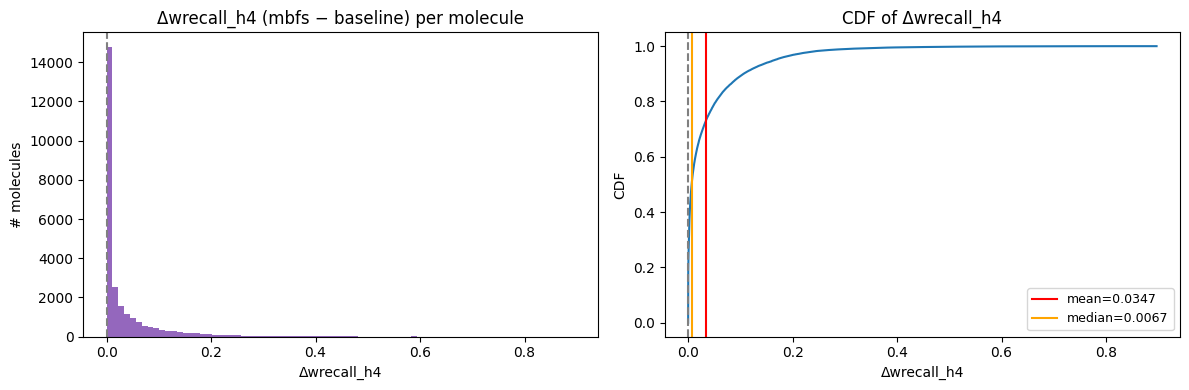

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].hist(mol_cmp["wrecall_h4_delta"], bins=80, color="tab:purple")
axes[0].axvline(0, color="gray", linestyle="--")
axes[0].set_title("Δwrecall_h4 (mbfs − baseline) per molecule")
axes[0].set_xlabel("Δwrecall_h4")
axes[0].set_ylabel("# molecules")

vals = mol_cmp["wrecall_h4_delta"].sort_values()
cdf = np.arange(1, len(vals) + 1) / len(vals)
axes[1].plot(vals, cdf)
axes[1].axvline(0, color="gray", linestyle="--")
axes[1].axvline(vals.mean(), color="red", label=f"mean={vals.mean():.4f}")
axes[1].axvline(vals.median(), color="orange", label=f"median={vals.median():.4f}")
axes[1].set_title("CDF of Δwrecall_h4")
axes[1].set_xlabel("Δwrecall_h4")
axes[1].set_ylabel("CDF")
axes[1].legend(fontsize=9)

plt.tight_layout()
plt.show()

In [6]:
# Attach SMILES/formula for readability
mol_meta = pd.read_pickle(PROC_DP / "mol_df.pkl")[["mol_id", "smiles", "formula", "mw"]].set_index("mol_id")

top_improved = (
    mol_cmp.join(mol_meta, how="left")
    .sort_values("wrecall_h4_delta", ascending=False)
    .head(30)
)
top_improved[["smiles", "formula", "mw", f"{WCOL}_baseline", f"{WCOL}_mbfs", "wrecall_h4_delta"]]

,smiles,formula,mw,wrecall_0.01_h4_baseline,wrecall_0.01_h4_mbfs,wrecall_h4_delta
mol_id,,,,,,
14951,CN(C)C(=S)SSC(=S)N(C)C,C6H12N2S4,240.444,0.102683,0.999327,0.896644
15124,CN(C)S(=O)(=O)n1nccc1Br,C5H8BrN3O2S,254.109,0.183369,1.000000,0.816631
14946,CN(C)C(=S)N(C)C,C5H12N2S,132.232,0.188040,0.998360,0.810320
31493,O=C1CC2OCC=C3CN4CCC56c7ccccc7N1C5C2C3CC46,C21H22N2O2,334.419,0.156408,0.917087,0.760679
34119,Oc1c2ccccc2c2c3c(cccc13)N=N2,C14H8N2O,220.231,0.241568,0.994121,0.752554
15421,CN1CCC23CCCCC2C1Cc1ccc(O)cc13,C17H23NO,257.377,0.235858,0.986384,0.750525
15651,CNC(=O)N(C)C,C4H10N2O,102.137,0.257209,0.999561,0.742351
16897,COC(=O)c1nsnc1Br,C4H3BrN2O2S,223.051,0.133325,0.875567,0.742242
15125,CN(C)S(N)(=O)=O,C2H8N2O2S,124.165,0.258446,0.994233,0.735788


## CMF breakdown (spec-level)

CMF status is a per-spectrum property of `prec_type`, not per-molecule (one molecule can be
measured under several adducts). Join `spec_stats_df` with `prec_type` from `spec_df.pkl` and
compare the same h4 delta, grouped by adduct class:

- **direct-charge**: `[M+H]+` / `[M-H]-` — only `delta_h=0` is a real CMF peak
- **cmf**: other adducts in `PREC_TYPE_TO_CMF_MASS_DIFF` — full charge-migration H-shift range applies
- **other**: adducts not covered by CMF logic at all

In [7]:
spec_meta = pd.read_pickle(PROC_DP / "spec_df.pkl")[["spec_id", "mol_id", "prec_type"]].copy()
spec_meta["spec_id"] = spec_meta["spec_id"].astype(str)


def classify_adduct(prec_type: str) -> str:
    if prec_type in DIRECT_CHARGE_PREC_TYPES:
        return "direct_charge"
    if prec_type in CMF_PREC_TYPES:
        return "cmf"
    return "other"


spec_meta["adduct_class"] = spec_meta["prec_type"].apply(classify_adduct)
print(spec_meta["adduct_class"].value_counts())

adduct_class
direct_charge    537510
other            457636
cmf              152926
Name: count, dtype: int64


In [8]:
base_spec = all_dfs["baseline"]["spec_stats_df"][["spec_id", WCOL]].copy()
mbfs_spec = all_dfs["mbfs"]["spec_stats_df"][["spec_id", WCOL]].copy()
base_spec["spec_id"] = base_spec["spec_id"].astype(str)
mbfs_spec["spec_id"] = mbfs_spec["spec_id"].astype(str)

base_spec = base_spec.set_index("spec_id")[WCOL]
mbfs_spec = mbfs_spec.set_index("spec_id")[WCOL]
common_specs = base_spec.index.intersection(mbfs_spec.index)
print(f"Spectra in common: {len(common_specs):,}")

spec_cmp = pd.DataFrame({
    f"{WCOL}_baseline": base_spec.loc[common_specs],
    f"{WCOL}_mbfs": mbfs_spec.loc[common_specs],
})
spec_cmp["wrecall_h4_delta"] = spec_cmp[f"{WCOL}_mbfs"] - spec_cmp[f"{WCOL}_baseline"]
spec_cmp = spec_cmp.join(spec_meta.set_index("spec_id")[["mol_id", "prec_type", "adduct_class"]], how="left")
print(f"Unmatched adduct_class (no spec_meta match): {spec_cmp['adduct_class'].isna().sum():,}")
spec_cmp = spec_cmp.dropna(subset=["adduct_class"])
spec_cmp.head()

Spectra in common: 490,173


Unmatched adduct_class (no spec_meta match): 0


,wrecall_0.01_h4_baseline,wrecall_0.01_h4_mbfs,wrecall_h4_delta,mol_id,prec_type,adduct_class
spec_id,,,,,,
0,0.883464,0.883464,0.0,10998,[M+NH4]+,cmf
1,0.903134,0.903134,0.0,10998,[M+NH4]+,cmf
2,0.973237,0.973237,0.0,10998,[M+NH4]+,cmf
3,0.855769,0.855769,0.0,10998,[M+NH4]+,cmf
4,1.000000,1.000000,0.0,10998,[M+NH4]+,cmf


In [9]:
group_summary = spec_cmp.groupby("adduct_class")["wrecall_h4_delta"].agg(
    ["count", "mean", "median", lambda s: (s > 1e-6).mean()]
)
group_summary.columns = ["n_spectra", "mean_delta", "median_delta", "frac_improved"]
group_summary

,n_spectra,mean_delta,median_delta,frac_improved
adduct_class,,,,
cmf,55654,0.017835,0.0,0.212707
direct_charge,434519,0.041240,0.0,0.451053


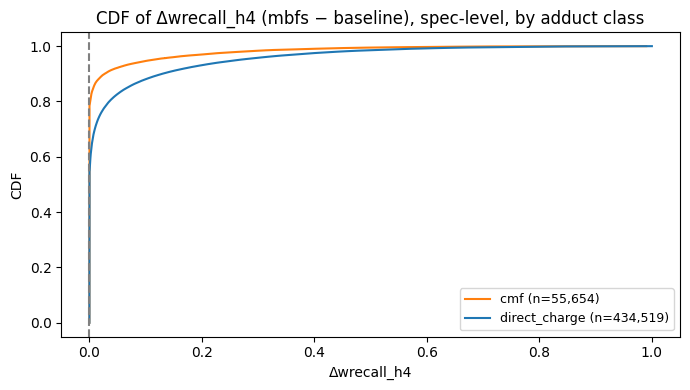

In [10]:
fig, ax = plt.subplots(figsize=(7, 4))
COLORS = {"direct_charge": "tab:blue", "cmf": "tab:orange", "other": "tab:gray"}
for cls, grp in spec_cmp.groupby("adduct_class"):
    vals = grp["wrecall_h4_delta"].sort_values()
    cdf = np.arange(1, len(vals) + 1) / len(vals)
    ax.plot(vals, cdf, label=f"{cls} (n={len(vals):,})", color=COLORS.get(cls))
ax.axvline(0, color="gray", linestyle="--")
ax.set_title("CDF of Δwrecall_h4 (mbfs − baseline), spec-level, by adduct class")
ax.set_xlabel("Δwrecall_h4")
ax.set_ylabel("CDF")
ax.legend(fontsize=9)
plt.tight_layout()
plt.show()

## Cross-reference: adduct mix of the top mol-level gainers

For the molecules with the biggest mol-level h4 wrecall gain, show which adduct class(es) their
spectra belong to — is the gain coming from CMF-adduct spectra, direct-charge spectra, or both?

In [11]:
top_mol_ids = top_improved.index
top_mol_adducts = (
    spec_cmp[spec_cmp["mol_id"].isin(top_mol_ids)]
    .groupby("mol_id")
    .agg(
        n_spectra=("adduct_class", "size"),
        adduct_classes=("adduct_class", lambda s: sorted(s.unique())),
        mean_spec_delta=("wrecall_h4_delta", "mean"),
    )
)
top_improved.join(top_mol_adducts)[
    ["smiles", "formula", "wrecall_h4_delta", "n_spectra", "adduct_classes", "mean_spec_delta"]
]

,smiles,formula,wrecall_h4_delta,n_spectra,adduct_classes,mean_spec_delta
mol_id,,,,,,
14951,CN(C)C(=S)SSC(=S)N(C)C,C6H12N2S4,0.896644,17,[direct_charge],0.821799
15124,CN(C)S(=O)(=O)n1nccc1Br,C5H8BrN3O2S,0.816631,9,[direct_charge],0.693342
14946,CN(C)C(=S)N(C)C,C5H12N2S,0.810320,18,[direct_charge],0.705205
31493,O=C1CC2OCC=C3CN4CCC56c7ccccc7N1C5C2C3CC46,C21H22N2O2,0.760679,9,[direct_charge],0.716425
34119,Oc1c2ccccc2c2c3c(cccc13)N=N2,C14H8N2O,0.752554,8,[direct_charge],0.663853
15421,CN1CCC23CCCCC2C1Cc1ccc(O)cc13,C17H23NO,0.750525,19,[direct_charge],0.579653
15651,CNC(=O)N(C)C,C4H10N2O,0.742351,16,[direct_charge],0.524698
16897,COC(=O)c1nsnc1Br,C4H3BrN2O2S,0.742242,16,[direct_charge],0.663938
15125,CN(C)S(N)(=O)=O,C2H8N2O2S,0.735788,11,[direct_charge],0.518491
